# Funktionen mehrerer Veränderlicher VI: Die implizite Funktion

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitt 2.7)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/06_implizite_funktion.ipynb)

**Inhalt**


1. Beispiel 2.7.1: eine lineare implizite Gleichung
2. Beispiele 2.7.2 und 2.7.3: Einheitskreis, zwei Lösungsäste, lokale Auflösbarkeit
3. Satz 2.7.4: Satz über die implizite Funktion und die Formel für $y'(x)$
4. Beispiel 2.7.5: Steigung einer Kurve im Punkt $P(0,1)$
5. Die Kurve als Niveaulinie $f(x,y) = 0$ einer Fläche


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax

## 1. Beispiel 2.7.1

Gegeben ist $f(x,y) = 3x + 2y - 4$. Die implizite Gleichung $f(x,y) = 0$ lässt sich global nach $y$ auflösen:
$$y(x) = -\tfrac{3}{2}x + 2,\qquad x\in\mathbb{R}.$$
Es gibt also genau eine Funktion $y:\mathbb{R}\to\mathbb{R}$ mit $f(x, y(x)) = 0$ für alle $x$.

In [2]:
f271 = 3*x + 2*y - 4
loesungen = sp.solve(sp.Eq(f271, 0), y)
display(sp.Eq(sp.Symbol('y(x)'), loesungen[0]))
pruefe('Skript-Ergebnis', loesungen[0] - (-sp.Rational(3, 2)*x + 2))
pruefe('f(x, y(x)) = 0', f271.subs(y, loesungen[0]))
print('Anzahl der Lösungen:', len(loesungen))

Probe Skript-Ergebnis: Residuum = 0  -> ok
Probe f(x, y(x)) = 0: Residuum = 0  -> ok
Anzahl der Lösungen: 1


## 2. Beispiele 2.7.2 und 2.7.3: der Einheitskreis

Für $f(x,y) = x^2 + y^2 - 1$ hat $f(x,y) = 0$ für $x\notin[-1,1]$ keine Lösung. Für $x\in(-1,1)$ gibt es **zwei** Lösungen,
$$y_1(x) = \sqrt{1 - x^2},\qquad y_2(x) = -\sqrt{1 - x^2}.$$
Betrachtet man nur Punkte in einer $\varepsilon$-Umgebung von $(x_0,y_0) = (0,1)$, etwa mit $\varepsilon = \tfrac{1}{2}$, so ist die Lösung dort eindeutig: $y(x) = \sqrt{1 - x^2}$. Die Gleichung ist **lokal** auflösbar.

In den Punkten $(\pm 1, 0)$ gilt $f_y = 2y = 0$: Dort hat der Kreis eine senkrechte Tangente, und in keiner Umgebung lässt sich $y$ eindeutig als Funktion von $x$ schreiben.

Probe f(x, -sqrt(1 - x**2)) = 0: Residuum = 0  -> ok
Probe f(x, sqrt(1 - x**2)) = 0: Residuum = 0  -> ok


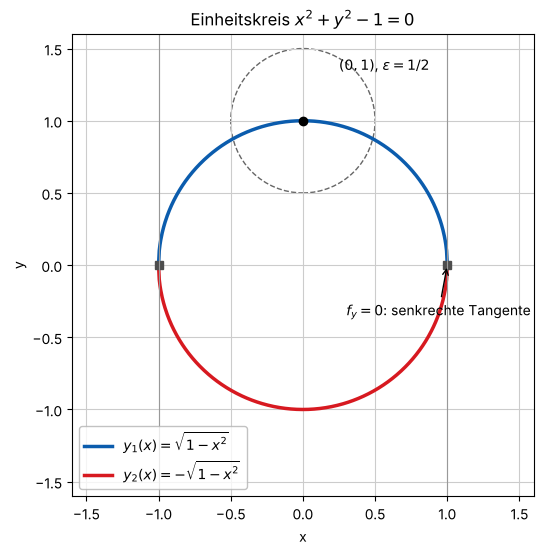

In [3]:
f272 = x**2 + y**2 - 1
aeste = sp.solve(sp.Eq(f272, 0), y)
display(aeste)
for ast in aeste:
    pruefe(f'f(x, {ast}) = 0', f272.subs(y, ast))

t = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(6, 6))
xs = np.linspace(-1, 1, 400)
ax.plot(xs, np.sqrt(1 - xs**2), color=BLAU, lw=2.5, label='$y_1(x) = \\sqrt{1-x^2}$')
ax.plot(xs, -np.sqrt(1 - xs**2), color=ROT, lw=2.5, label='$y_2(x) = -\\sqrt{1-x^2}$')
ax.add_patch(plt.Circle((0, 1), 0.5, fill=False, ls='--', color='0.4'))
ax.plot(0, 1, 'ko'); ax.annotate('$(0,1)$, $\\varepsilon = 1/2$', (0, 1), (0.25, 1.35))
for s in (-1, 1):
    ax.plot(s, 0, 's', color='0.3')
    ax.axvline(s, color='0.6', lw=0.8)
ax.annotate('$f_y = 0$: senkrechte Tangente', (1, 0), (0.3, -0.35), arrowprops=dict(arrowstyle='->'))
ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect='equal', xlabel='x', ylabel='y',
       title='Einheitskreis $x^2 + y^2 - 1 = 0$')
ax.legend(loc='lower left')
plt.show()

## 3. Satz 2.7.4: Satz über die implizite Funktion

Ist $f$ auf einem offenen Rechteck $D = (a,b)\times(c,d)$ mit stetigen partiellen Ableitungen $f_x, f_y$ gegeben, $f(x_0,y_0) = 0$ und $f_y(x_0,y_0)\neq 0$, dann gibt es Intervalle $U$ um $x_0$, $V$ um $y_0$ und eine differenzierbare Funktion $y:U\to V$ mit $y(x_0) = y_0$, $f(x, y(x)) = 0$ und
$$y'(x) = -\frac{f_x(x, y(x))}{f_y(x, y(x))}\qquad\text{für alle } x\in U.$$
Dabei ist die Lösung in $U\times V$ eindeutig: Für $(x,y)\in U\times V$ gilt $f(x,y) = 0$ genau dann, wenn $y = y(x)$.

Die Formel erhält man durch Ableiten von $f(x, y(x)) = 0$ mit der Kettenregel: $f_x + f_y\,y' = 0$.

**Probe am Einheitskreis:** $y' = -\frac{2x}{2y} = -\frac{x}{y}$. Für den oberen Ast $y_1 = \sqrt{1-x^2}$ muss das mit der direkt berechneten Ableitung übereinstimmen.

Probe y1'(x) = -f_x/f_y: Residuum = 0  -> ok


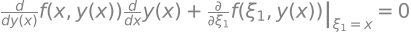

In [4]:
y1 = sp.sqrt(1 - x**2)
formel = (-sp.diff(f272, x)/sp.diff(f272, y)).subs(y, y1)
pruefe("y1'(x) = -f_x/f_y", sp.diff(y1, x) - formel)

# Allgemein: Kettenregel für f(x, y(x)) = 0
yf = sp.Function('y')(x)
F = sp.Function('f')
abl = sp.diff(F(x, yf), x)
display(sp.Eq(abl, 0))

**Interaktiv:** Ein Punkt läuft auf dem Kreis. Die Tangente hat die Steigung $y' = -x/y$. Nahe $(\pm 1, 0)$ wird $f_y$ klein und die Steigung betragsmäßig groß; in $(\pm 1, 0)$ selbst ist der Satz nicht anwendbar.

IntSlider(value=60, continuous_update=False, description='Winkel', max=359)

Output()

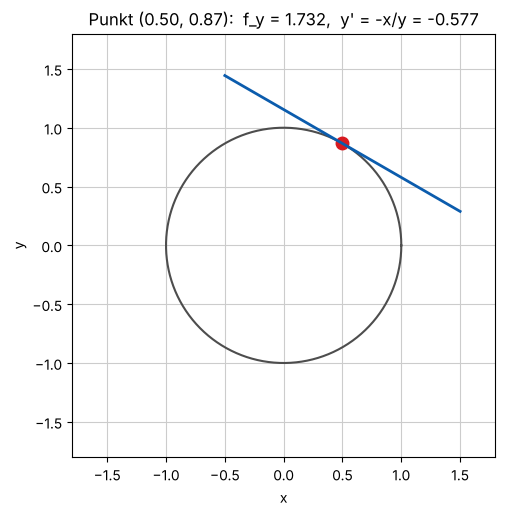

In [5]:
def zeige_tangente(winkel=60):
    phi = np.deg2rad(winkel)
    x0, y0 = np.cos(phi), np.sin(phi)
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot(np.cos(t), np.sin(t), color='0.3')
    ax.plot(x0, y0, 'o', color=ROT, ms=9)
    if abs(y0) > 1e-3:
        m = -x0/y0
        xs = np.linspace(x0 - 1, x0 + 1, 2)
        ax.plot(xs, y0 + m*(xs - x0), color=BLAU, lw=2)
        info = f"f_y = {2*y0:.3f},  y' = -x/y = {m:.3f}"
    else:
        ax.axvline(x0, color=BLAU, lw=2)
        info = 'f_y = 0: Satz 2.7.4 nicht anwendbar'
    ax.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), aspect='equal', xlabel='x', ylabel='y',
           title=f'Punkt ({x0:.2f}, {y0:.2f}):  {info}')
    plt.show()


w_r = widgets.IntSlider(value=60, min=0, max=359, step=1, description='Winkel', continuous_update=False)
display(w_r, widgets.interactive_output(zeige_tangente, {'winkel': w_r}))

# Statische Vorschau für GitHub.
zeige_tangente()

## 4. Beispiel 2.7.5

Welche Steigung besitzt die Kurve
$$(x^2 + y^2)^2 - 2x(x^2 + y^2) - y^2 = 0$$
im Kurvenpunkt $P(0,1)$?

Mit $f(x,y) = (x^2+y^2)^2 - 2x(x^2+y^2) - y^2$ ist $f(0,1) = 1 - 0 - 1 = 0$, der Punkt liegt also auf der Kurve. Die partiellen Ableitungen sind
$$f_x(x,y) = 4x(x^2+y^2) - 6x^2 - 2y^2,\qquad f_y(x,y) = 4y(x^2+y^2) - 4xy - 2y.$$
Wegen $f_y(0,1) = 4 - 2 = 2\neq 0$ gilt nach Satz 2.7.4
$$y'(0) = -\frac{f_x(0,1)}{f_y(0,1)} = -\frac{-2}{2} = 1.$$
Die Tangente in $P$ lautet $y = x + 1$.

Probe P liegt auf der Kurve: Residuum = 0  -> ok
Probe f_x laut Skript: Residuum = 0  -> ok
Probe f_y laut Skript: Residuum = 0  -> ok
f_x(0,1) = -2 ,  f_y(0,1) = 2 ,  y'(0) = 1
Probe y'(0) = 1: Residuum = 0  -> ok


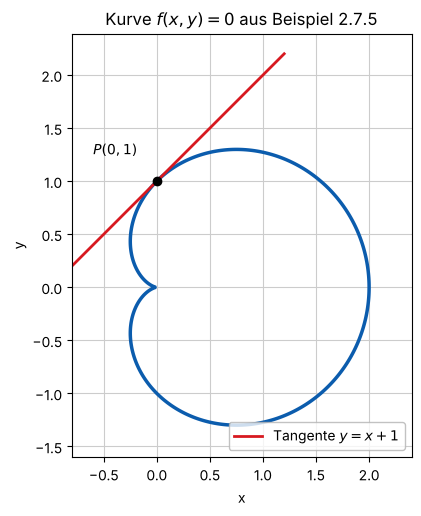

In [6]:
f275 = (x**2 + y**2)**2 - 2*x*(x**2 + y**2) - y**2
fx, fy = sp.diff(f275, x), sp.diff(f275, y)
pruefe('P liegt auf der Kurve', f275.subs({x: 0, y: 1}))
pruefe('f_x laut Skript', fx - (4*x*(x**2 + y**2) - 6*x**2 - 2*y**2))
pruefe('f_y laut Skript', fy - (4*y*(x**2 + y**2) - 4*x*y - 2*y))
steigung = (-fx/fy).subs({x: 0, y: 1})
print('f_x(0,1) =', fx.subs({x: 0, y: 1}), ',  f_y(0,1) =', fy.subs({x: 0, y: 1}), ",  y'(0) =", steigung)
pruefe("y'(0) = 1", steigung - 1)

f275n = sp.lambdify((x, y), f275, 'numpy')
X, Y = np.meshgrid(np.linspace(-0.8, 2.4, 500), np.linspace(-1.6, 1.6, 500))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.contour(X, Y, f275n(X, Y), levels=[0], colors=[BLAU], linewidths=2.5)
xs = np.linspace(-0.8, 1.2, 2)
ax.plot(xs, xs + 1, color=ROT, lw=2, label='Tangente $y = x + 1$')
ax.plot(0, 1, 'ko'); ax.annotate('$P(0,1)$', (0, 1), (-0.6, 1.25))
ax.set(aspect='equal', xlabel='x', ylabel='y', title='Kurve $f(x,y) = 0$ aus Beispiel 2.7.5')
ax.legend(loc='lower right')
plt.show()

## 5. Die Kurve als Niveaulinie

Die Kurve aus Beispiel 2.7.5 ist die Niveaulinie $f(x,y) = 0$ der Fläche $z = f(x,y)$. Der Gradient $\nabla f(0,1) = (-2,\ 2)^T$ steht senkrecht auf ihr; die Tangentenrichtung $(1,\ 1)^T$ (Steigung 1) erfüllt $(-2,\ 2)\cdot(1,\ 1) = 0$.

Probe Gradient senkrecht zur Tangente: Residuum = 0  -> ok


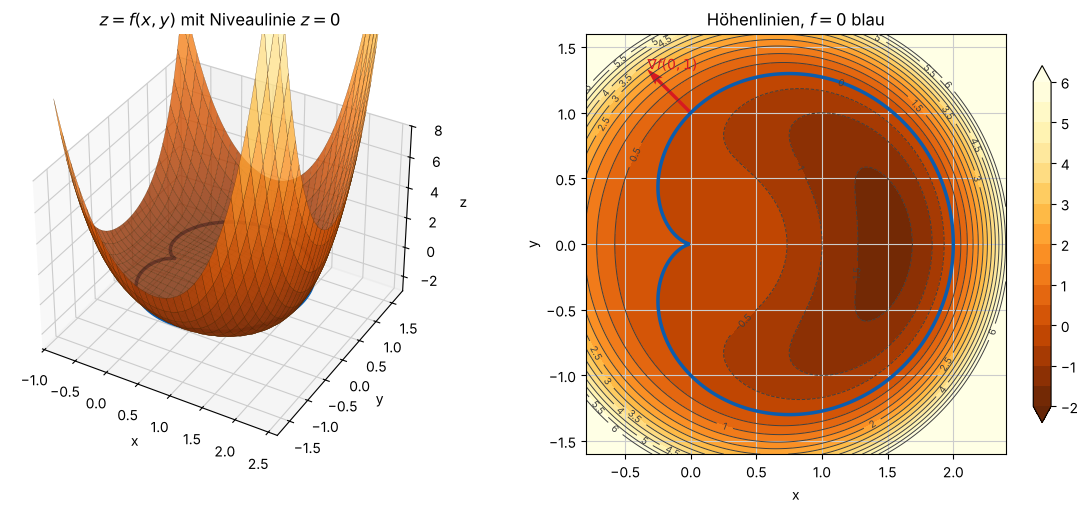

In [7]:
grad = sp.Matrix([fx, fy]).subs({x: 0, y: 1})
pruefe('Gradient senkrecht zur Tangente', grad.dot(sp.Matrix([1, 1])))

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
flaeche(f275n, (-0.8, 2.4), (-1.6, 1.6), ax=ax1, titel='$z = f(x,y)$ mit Niveaulinie $z = 0$', alpha=0.8, blick=(35, -60))
ax1.contour(X, Y, f275n(X, Y), levels=[0], colors=[BLAU], linewidths=2.5, offset=0)
ax1.set_zlim(-3, 8)
ax2 = fig.add_subplot(1, 2, 2)
hoehenlinien(f275n, (-0.8, 2.4), (-1.6, 1.6), ax=ax2, niveaus=np.linspace(-2, 6, 17), titel='Höhenlinien, $f = 0$ blau')
ax2.contour(X, Y, f275n(X, Y), levels=[0], colors=[BLAU], linewidths=2.5)
ax2.quiver(0, 1, -2, 2, angles='xy', scale_units='xy', scale=6, color=ROT, width=0.008)
ax2.annotate('$\\nabla f(0,1)$', (-0.33, 1.33), color=ROT)
plt.tight_layout(); plt.show()